![Logo](LogoCab.png)

# Introduction and Project Context

Amazing Creative Desk Coworking (ACDC) operates in a competitive coworking market with a diverse member base, where customers can differ considerably in terms of their membership plans, usage patterns, and engagement with the available services. Understanding these differences is important for identifying distinct customer groups and developing strategies that better respond to their needs.

This project focuses on the analysis of ACDC’s membership and space-usage data collected over a three-year period. By exploring customer characteristics, membership information, and behavioural patterns, the aim is to identify meaningful segments within the customer base. These insights can then be used to support a more targeted marketing strategy, helping ACDC improve customer satisfaction, retention, and overall business performance.

The analysis follows a data-driven approach to customer segmentation, considering different perspectives such as customer value and usage behaviour. The results of this analysis will provide the basis for the subsequent clustering process and the development of actionable business recommendations.

# Importing Libraries

In [43]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import sqlite3
import os
from math import ceil, floor
from math import radians, sin, cos, sqrt, atan2
from sklearn.experimental import enable_iterative_imputer 
from sklearn.impute import IterativeImputer
from itertools import combinations
import scipy.stats as ss
from sklearn.preprocessing import RobustScaler
from IPython.display import HTML, display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# For better resolution plots
%config InlineBackend.figure_format = 'retina' 

# Set theme for seaborn
sns.set_theme(style="whitegrid")

# Import Dataset

In this section, we load the coworking dataset from the CSV file using semicolons as column separators. We also perform an initial data quality check to identify and remove any duplicate records, ensuring that each member entry is unique before proceeding with the exploratory data analysis and modeling phases.

In [44]:
dataset = pd.read_csv("../data/acdc_dataset.csv",sep = ";", index_col= 'member_id')

# Metadata

In this section, we outline the variables included in the ACDC dataset. A clear understanding of the definition, type, and nature of each attribute is crucial for correctly interpreting customer behaviors, guiding feature engineering, and supporting the subsequent segmentation process.
This information is taken directly from the annex of the guidelines document.

In [45]:
metadata_dict = {
    "member_id": "Unique identifier of each member",
    "age": "Age of the member at the extraction date",
    "gender": "Gender of the member",
    "country": "The country where the member (or their associated company) is based",
    "industry": "The industry sector the member works in",
    "is_team_account": "Whether the membership is held by a team/company account rather than an individual",
    "n_colleagues_on_account": "Number of colleagues sharing the account",
    "plan_tier": "Current membership tier (hot_desk < flex < dedicated_desk < full_time < private_office)",
    "plan_days_per_week": "Number of days per week the member's plan entitles them to use the space",
    "membership_start": "Date the membership first began",
    "membership_end": "Date the membership first ended",
    "last_badge_swipe": "Date of the member's most recent physical entry to the space",
    "days_since_last_visit": "Number of days since the member's last recorded visit",
    "total_visits": "Total number of visits the member made over the whole membership",
    "avg_weekly_visits": "Average number of visits per week over the membership",
    "entitled_visits_last_period": "Number of visits the member's plan entitled them to during the last period of their membership",
    "actual_visits_last_period": "Number of visits the member actually made during the last period of their membership",
    "meeting_room_hours": "Hours of meeting-room usage recorded for the member",
    "event_space_hours": "Hours of event-space usage recorded for the member",
    "guest_passes_issued": "Number of guest passes the member issued",
    "uses_meeting_rooms": "Whether the member ever used the meeting-room add-on",
    "uses_event_space": "Whether the member ever used the event-space add-on",
    "uses_guest_passes": "Whether the member ever used the guest-pass add-on",
    "uses_print": "Whether the member used the print add-on",
    "uses_mail_handling": "Whether the member used the mail-handling add-on",
    "uses_phone_booths": "Whether the member used the phone-booth add-on",
    "uses_day_passes": "Whether the member used the day-pass add-on",
    "uses_storage": "Whether the member used the storage add-on",
    "uses_bike_locker": "Whether the member used the bike-locker add-on",
    "n_renewals": "Number of times the membership was renewed",
    "lifetime_value": "Total revenue attributed to the member over the whole membership"
}

# convert the metadata dictionary to a DataFrame for better visualization
df_meta = pd.DataFrame(list(metadata_dict.items()), columns=["Variable", "Description"]).set_index("Variable")

# Set pandas display options to show all rows and columns without truncation
pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_columns', None)

df_meta

,Description
Variable,
member_id,Unique identifier of each member
age,Age of the member at the extraction date
gender,Gender of the member
country,The country where the member (or their associated company) is based
industry,The industry sector the member works in
is_team_account,Whether the membership is held by a team/company account rather than an individual
n_colleagues_on_account,Number of colleagues sharing the account
plan_tier,Current membership tier (hot_desk < flex < dedicated_desk < full_time < private_office)
plan_days_per_week,Number of days per week the member's plan entitles them to use the space


# General Look at the DataSet

In [46]:
print('Dataset shape:', dataset.shape)

Dataset shape: (15465, 30)


In [47]:
dataset.head()

,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,last_badge_swipe,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,uses_meeting_rooms,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
member_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
CW000001,38.0,Female,Information Technology,Portugal,False,0,flex,3,2021-08-01,2023-03-06,2023-03-23,-17,220,2.65,26.09,22,0.0,0.0,18.0,False,False,True,0,False,True,True,False,False,2,4477.97
CW000002,38.0,Male,Information Technology,Portugal,True,2,HOT_DESK,2,2023-11-24,1970-01-01,2023-11-24,37,2,0.32,10.68,1,0.0,0.0,0.0,False,False,False,0,True,False,False,False,False,0,165.86
CW000003,43.0,Male,Education,DE,True,1,flex,3,2021-12-03,1970-01-01,2023-07-22,163,19,0.17,26.09,2,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,1,4486.17
CW000004,38.0,F,Legal,portugal,False,0,flex,3,2022-01-02,2022-02-15,2022-01-02,44,8,1.23,18.74,9,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,0,258.63
CW000005,45.0,Female,Information Technology,United Kingdom,False,0,hot_desk,2,2023-10-24,1970-01-01,2023-12-17,15,4,0.38,17.39,3,0.0,0.0,0.0,False,False,False,0,False,False,True,False,False,0,335.74


In [48]:
dataset.tail()

,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,last_badge_swipe,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,uses_meeting_rooms,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
member_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
CW009828,29.0,Female,Unknown,Spain,False,0,flex,3,2022-12-09,2023-07-01,2023-06-28,3,74,2.55,26.09,21,0.0,0.0,0.0,False,False,False,1,True,True,False,False,False,0,1422.36
CW005287,19.0,Female,Information Technology,Germany,False,0,private_office,7,2021-04-29,2023-10-15,2023-09-26,19,74,0.58,60.87,4,0.0,0.0,0.0,False,False,False,0,True,True,False,True,False,0,20683.24
CW003868,28.0,Female,Design & Creative,Portugal,True,1,hot_desk,2,2023-12-27,1970-01-01,2023-12-27,5,1,0.21,1.31,0,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,0,18.14
CW013132,32.0,Female,Legal,Portugal,False,0,dedicated_desk,5,2021-08-28,2023-10-06,2023-10-04,2,407,3.71,43.48,31,30.1,17.6,0.0,True,True,False,1,False,True,True,True,False,4,11834.5
CW015101,46.0,Male,Information Technology,Portugal,False,0,flex,3,2022-02-04,2022-04-19,2022-02-12,66,5,0.45,26.09,4,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,0,435.82


In [49]:
dataset.columns

Index(['age', 'gender', 'industry', 'country', 'is_team_account',
       'n_colleagues_on_account', 'plan_tier', 'plan_days_per_week',
       'membership_start', 'membership_end', 'last_badge_swipe',
       'days_since_last_visit', 'total_visits', 'avg_weekly_visits',
       'entitled_visits_last_period', 'actual_visits_last_period',
       'meeting_room_hours', 'event_space_hours', 'guest_passes_issued',
       'uses_meeting_rooms', 'uses_event_space', 'uses_guest_passes',
       'uses_print', 'uses_mail_handling', 'uses_phone_booths',
       'uses_day_passes', 'uses_storage', 'uses_bike_locker', 'n_renewals',
       'lifetime_value'],
      dtype='object')

# Data Quality Check

In [50]:
df_meta["Data Type"] = dataset.dtypes
df_meta

,Description,Data Type
Variable,,
member_id,Unique identifier of each member,NaN
age,Age of the member at the extraction date,float64
gender,Gender of the member,object
country,The country where the member (or their associated company) is based,object
industry,The industry sector the member works in,object
is_team_account,Whether the membership is held by a team/company account rather than an individual,bool
n_colleagues_on_account,Number of colleagues sharing the account,int64
plan_tier,Current membership tier (hot_desk < flex < dedicated_desk < full_time < private_office),object
plan_days_per_week,Number of days per week the member's plan entitles them to use the space,int64


In [51]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
Index: 15465 entries, CW000001 to CW015101
Data columns (total 30 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   age                          14907 non-null  float64
 1   gender                       14935 non-null  object 
 2   industry                     15465 non-null  object 
 3   country                      15035 non-null  object 
 4   is_team_account              15465 non-null  bool   
 5   n_colleagues_on_account      15465 non-null  int64  
 6   plan_tier                    15360 non-null  object 
 7   plan_days_per_week           15465 non-null  int64  
 8   membership_start             15465 non-null  object 
 9   membership_end               15465 non-null  object 
 10  last_badge_swipe             15465 non-null  object 
 11  days_since_last_visit        15465 non-null  int64  
 12  total_visits                 15465 non-null  int64  
 13  avg_weekly_

In this section, we review the data types (`dtypes`) of each feature to ensure they are correctly formatted for subsequent exploratory analysis and clustering algorithms. Based on our structural inspection (`df.info()`), several discrepancies and necessary type conversions have been identified:

`member_id` isn't listed here because it became the index

date variables (`membership_ends`, `membership_starts` and `last_badge_swipe`) are currently cast as String(`object`) but should be cast to `dateTime`.

`age` and `guest_passes_issued` are currently stored as float64 due to the presence of missing values. Since both represent a discrete value,  these variables should be converted to integer (`int`) after handling the missing values.

`entitled_visits_last_period` represents the "number of visits the member's plan entitled them to during the last period of their membership" and this intuitively seems like it should be stored as an `int` but it is stored as a `float`, this needs further looking into. The hypothesis is that it is a calculated number from other variables.

`uses_print` represents binary usage but is currently stored as numeric integer (`int64`). It should be cast to boolean (`bool`) to match the other binary flags in the dataset (e.g., `uses_meeting_rooms`, `uses_phone_booths`).

Lifetime Value (`lifetime_value`): Currently stored as an object (`string`) instead of a numeric type. This hints at the presence of formatting characters (such as currency symbols or spaces) that must be cleaned, parsed, and converted to `float` to correctly measure the economic contribution of each member.

In [52]:
temp_df = dataset.copy()
temp_df.drop(columns=["uses_print"]).describe().T

,count,mean,std,min,25%,50%,75%,max
age,14907.0,34.858724,10.394649,1.0,29.00,34.00,40.00,149.00
n_colleagues_on_account,15465.0,0.537019,1.177668,-1.0,0.00,0.00,1.00,9.00
plan_days_per_week,15465.0,3.387262,1.458818,0.0,2.00,3.00,5.00,9.00
days_since_last_visit,15465.0,117.109279,275.532807,-956.0,4.00,13.00,55.00,1212.00
total_visits,15465.0,110.406531,182.939340,-112.0,8.00,34.00,132.00,6530.00
avg_weekly_visits,15465.0,1.777214,1.937515,0.0,0.71,1.42,2.41,47.40
entitled_visits_last_period,15465.0,27.517393,13.480235,0.0,17.39,26.09,43.48,78.27
actual_visits_last_period,15465.0,13.800970,11.387207,0.0,5.00,10.00,20.00,60.00
meeting_room_hours,14167.0,33.075570,428.169678,-56.6,0.00,0.00,7.20,41220.00
event_space_hours,15465.0,5.117220,26.013097,-13.5,0.00,0.00,0.00,602.80


The descriptive statistics (`df.describe()`) reveal several interesting patterns alongside notable data quality anomalies that require careful consideration. Specifically, we observe extreme values and physically impossible entries (such as negative numbers in visits, renewal counts, and meeting room hours, as well as outliers like an age of 149 years).

Furthermore, a large proportion of members show low space utilization compared to their plan entitlements. These preliminary findings highlight the need for targeted data cleaning and deeper behavioral investigation before defining our final customer segmentation strategy.

In [53]:
dataset.describe(include='object').T

,count,unique,top,freq
gender,14935,12,Female,7414
industry,15465,43,Information Technology,3322
country,15035,33,Portugal,9959
plan_tier,15360,19,flex,5182
membership_start,15465,1539,2021-01-01,560
membership_end,15465,1423,1970-01-01,3956
last_badge_swipe,15465,1543,2023-12-30,279
lifetime_value,14425,11860,0,1725


This descriptive statistic for the `object` types shows us that we have 12 unique genders which might be errors or different ways of writing like "Female", "female", "fem", "f" , " female", this needs to be confirmed and fixed. Most customers are from Portugal.

We have 3956 members which membership has ended 50 years ago, this is either an error and needs to be fixed or the default "zero" date that systems write when the field is empty or in other words "no end date yet"

We can also confirm lifetime value(`lifetime_value`) is a numeric value due to the proportion of uniques, we can also see 1725 members have a membership but haven't made spent anything (the lifetime_value is `0`) which can mean that they just started their membership, this needs further looking into.

In [54]:
summary = pd.DataFrame({
    "Non-null values": dataset.count(),
    "Unique values": dataset.nunique(),
    "Missing count": dataset.isnull().sum(),
    "Missing %": dataset.isnull().mean() * 100,
    "Negative values": (dataset.select_dtypes(include=[np.number]) < 0).sum(),
})

summary

,Non-null values,Unique values,Missing count,Missing %,Negative values
actual_visits_last_period,15465,61,0,0.000000,0.0
age,14907,84,558,3.608147,0.0
avg_weekly_visits,15465,616,0,0.000000,0.0
country,15035,33,430,2.780472,NaN
days_since_last_visit,15465,430,0,0.000000,56.0
entitled_visits_last_period,15465,1876,0,0.000000,0.0
event_space_hours,15465,824,0,0.000000,8.0
gender,14935,12,530,3.427093,NaN
guest_passes_issued,14194,205,1271,8.218558,7.0
industry,15465,43,0,0.000000,NaN


The table above tells us how many unique values, how many missing and, if numeric, how many negatives each feature has. We have to keep in mind that there might be missing values in other forms for example a country that doesnt exist.

# Deeper Analysis

## Unique

In [55]:
for column in dataset.columns:
    unique_values = dataset[column].unique()
    print(f"Unique values on the column '{column}': {unique_values}")
    print('-----------------------------------')
    print('')

Unique values on the column 'age': [ 38.  43.  45.  39.  23.  33.  30.  44.  37. 131.  20.  40.  32.  21.
  29.  25.  28.  51.  41.  nan  31.  42.  34.  36.  50.  24.  19.  47.
  54.  26.  53.  27.  46.  18.  48.  63.  35.  22.  59.  49.   4.   3.
  58.  72.   9.   8.  57.  52.  73. 132.  60.  55. 144.  61.   1.   6.
 141.   2.   7. 137.  66. 147. 140. 142.  56.  62. 145.   5.  65.  83.
  14. 138. 136. 146. 134.  70.  74.  93.  92. 143. 139.  91.  64. 149.
 135.]
-----------------------------------

Unique values on the column 'gender': ['Female' 'Male' 'F' 'Other' nan ' Female' 'M' 'male' ' Male' 'other'
 ' Other' 'female' 'O']
-----------------------------------

Unique values on the column 'industry': ['Information Technology' 'Education' 'Legal' 'Health' 'Unknown' 'Other'
 'Consulting' 'Design & Creative' 'information technology' 'Finance'
 'Marketing & PR' 'EDUCATION' 'DESIGN & CREATIVE' 'Marketing and PR'
 'Real Estate' 'other' 'consulting' 'MARKETING & PR'
 'Information technolo

Here we can see that the date columns have two distinct formats being used at the same time, `YYYY-MM-DD` and `DD/MM/YYYY`. This can be due to different nationalities using different date time formats, either way all need to be in the same format.

In the `plan_tier` we can see "HOT_DESK", "hot_desk", "hot desk", "hotdesk" which all refer to the same, this happens in almost every other String column line Portugal, portugal, PT in country, in industry the same also happens etc so we can confirm the uniques are overinflated and that the 12 genders are indeed a mistake and that there should be 3, female, male and other.

In `age` we also see that there are some questionable numbers like minors from age 1 to 14 and people aged 120+. And in `industry` there is also "unknown" that should be "other".

## Values Count

In [56]:
for column in dataset.columns:
    unique_values = dataset[column].value_counts()
    print(f"The number of the distinct values in the column '{column}': {unique_values}")
    print('-----------------------------------')
    print('')

The number of the distinct values in the column 'age': age
34.0     710
31.0     679
32.0     658
36.0     655
35.0     650
33.0     647
38.0     637
37.0     626
30.0     619
29.0     597
39.0     588
40.0     546
28.0     528
41.0     516
42.0     474
27.0     450
26.0     449
43.0     422
25.0     420
24.0     372
44.0     357
23.0     333
45.0     303
22.0     290
21.0     269
46.0     250
47.0     242
20.0     214
48.0     187
49.0     175
19.0     169
50.0     124
51.0     109
52.0     105
53.0      80
18.0      73
54.0      64
55.0      36
3.0       26
4.0       26
56.0      26
58.0      25
57.0      22
59.0      14
61.0      11
9.0       11
60.0      10
141.0      9
2.0        8
7.0        8
131.0      7
63.0       7
8.0        6
6.0        6
62.0       5
5.0        4
140.0      4
83.0       4
134.0      4
72.0       3
135.0      3
66.0       3
132.0      3
144.0      2
93.0       2
142.0      2
65.0       2
1.0        2
136.0      2
64.0       2
146.0      2
73.0       1
145.0

## Check Duplicates Values

In [57]:
#Check how many duplicates exist
print(f"number of duplicates: {dataset.duplicated().sum()}")

#check the percentage of duplicates in our DataFrame
print(f"percentage of duplicates: {dataset.duplicated().sum() / len(dataset) * 100:.2f}%")

print(f"number of duplicate indices: {dataset.index.duplicated().sum()}")

number of duplicates: 182
percentage of duplicates: 1.18%
number of duplicate indices: 15


With `member_id` as the index, `duplicated()` compares the 30 feature columns and finds 182 repeated rows. Checking the index separately shows 15 repeated IDs, all exact copies of an earlier row. The remaining 182-15=167 rows are identical to another member in every field, including dates and lifetime value, but have a different ID. They are most likely the same member registered twice. We remove all 182, keeping the first occurrence, so that no member counts twice in the clustering.

In [58]:
#we drop the duplicates from the DataFrame with index
dataset.drop_duplicates(inplace= True)

# Check that the duplicates were removed
dataset.duplicated().sum()

np.int64(0)

## Correlation between Variables

In this section, we examine the relationships between numerical variables using a correlation matrix. This allows us to identify strong associations, potential redundancies, and patterns that may inform further analysis or feature selection.

We use **Spearman** correlation as our main measure. Pearson only captures straight-line relationships and can be dominated by a few extreme values, while Spearman is computed on the ranks of the values, so it measures whether two variables tend to increase (or decrease) together, regardless of the shape of the relationship or of extreme values. This suits our data, which is highly skewed, still contains extreme values and placeholders (e.g. `999` in `days_since_last_visit`), and includes ordered counts such as `plan_days_per_week` and `n_renewals`. Pearson is computed only to compare the two methods.

Note that `lifetime_value` is not included yet, as it is still stored as text, and that these correlations are computed before cleaning the data. They are therefore preliminary and will be revisited after the data cleaning step.

In [59]:
acdc_numeric_subset = dataset[[
    'age',
    'n_colleagues_on_account',
    'plan_days_per_week',
    'days_since_last_visit',
    'total_visits',
    'avg_weekly_visits',
    'entitled_visits_last_period',
    'actual_visits_last_period',
    'meeting_room_hours',
    'event_space_hours',
    'guest_passes_issued',
    'n_renewals'
]]

# Spearman is our main measure; Pearson is computed only for comparison
corr_spearman = acdc_numeric_subset.corr(method="spearman")
corr_pearson = acdc_numeric_subset.corr(method="pearson")

# Mask for the upper triangle and the diagonal (mirror image and self-correlations),
# so that each pair of variables appears only once
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

# Compare both methods for every pair of variables
corr_comparison = pd.DataFrame({
    "Pearson": corr_pearson.where(~mask).stack(),
    "Spearman": corr_spearman.where(~mask).stack()
})
corr_comparison["Difference"] = corr_comparison["Spearman"] - corr_comparison["Pearson"]

# Pairs where the two methods disagree the most
corr_comparison.sort_values("Difference", key=abs, ascending=False).head(10).round(2)

Pearson  Spearman  \
avg_weekly_visits         days_since_last_visit        -0.14     -0.65   
actual_visits_last_period days_since_last_visit        -0.18     -0.61   
total_visits              days_since_last_visit        -0.12     -0.51   
meeting_room_hours        total_visits                  0.06      0.40   
                          actual_visits_last_period     0.04      0.32   
                          avg_weekly_visits             0.02      0.30   
actual_visits_last_period avg_weekly_visits             0.66      0.93   
event_space_hours         meeting_room_hours            0.05      0.32   
guest_passes_issued       meeting_room_hours            0.08      0.34   
meeting_room_hours        days_since_last_visit        -0.02     -0.26   

                                                     Difference  
avg_weekly_visits         days_since_last_visit           -0.52  
actual_visits_last_period days_since_last_visit           -0.44  
total_visits              days_since_last_visit           -0.39  
meeting_room_hours        total_visits                     0.34  
                          actual_visits_last_period        0.27  
                          avg_weekly_visits                0.27  
actual_visits_last_period avg_weekly_visits                0.27  
event_space_hours         meeting_room_hours               0.27  
guest_passes_issued       meeting_room_hours               0.26  
meeting_room_hours        days_since_last_visit           -0.24

Most of the pairs where the two methods disagree involve `days_since_last_visit` and `meeting_room_hours`, precisely the variables that contain placeholders (`999`) and extreme values (up to 41,220 hours). For example, Pearson suggests almost no relationship between `days_since_last_visit` and `avg_weekly_visits` (-0.14), while Spearman shows a strong negative one (-0.65): members who visit more often have fewer days since their last visit. Pearson also underestimates how similar `actual_visits_last_period` and `avg_weekly_visits` are (0.66 vs 0.93). This confirms that Pearson is distorted by these values in our raw data, so we rely on Spearman from here on.

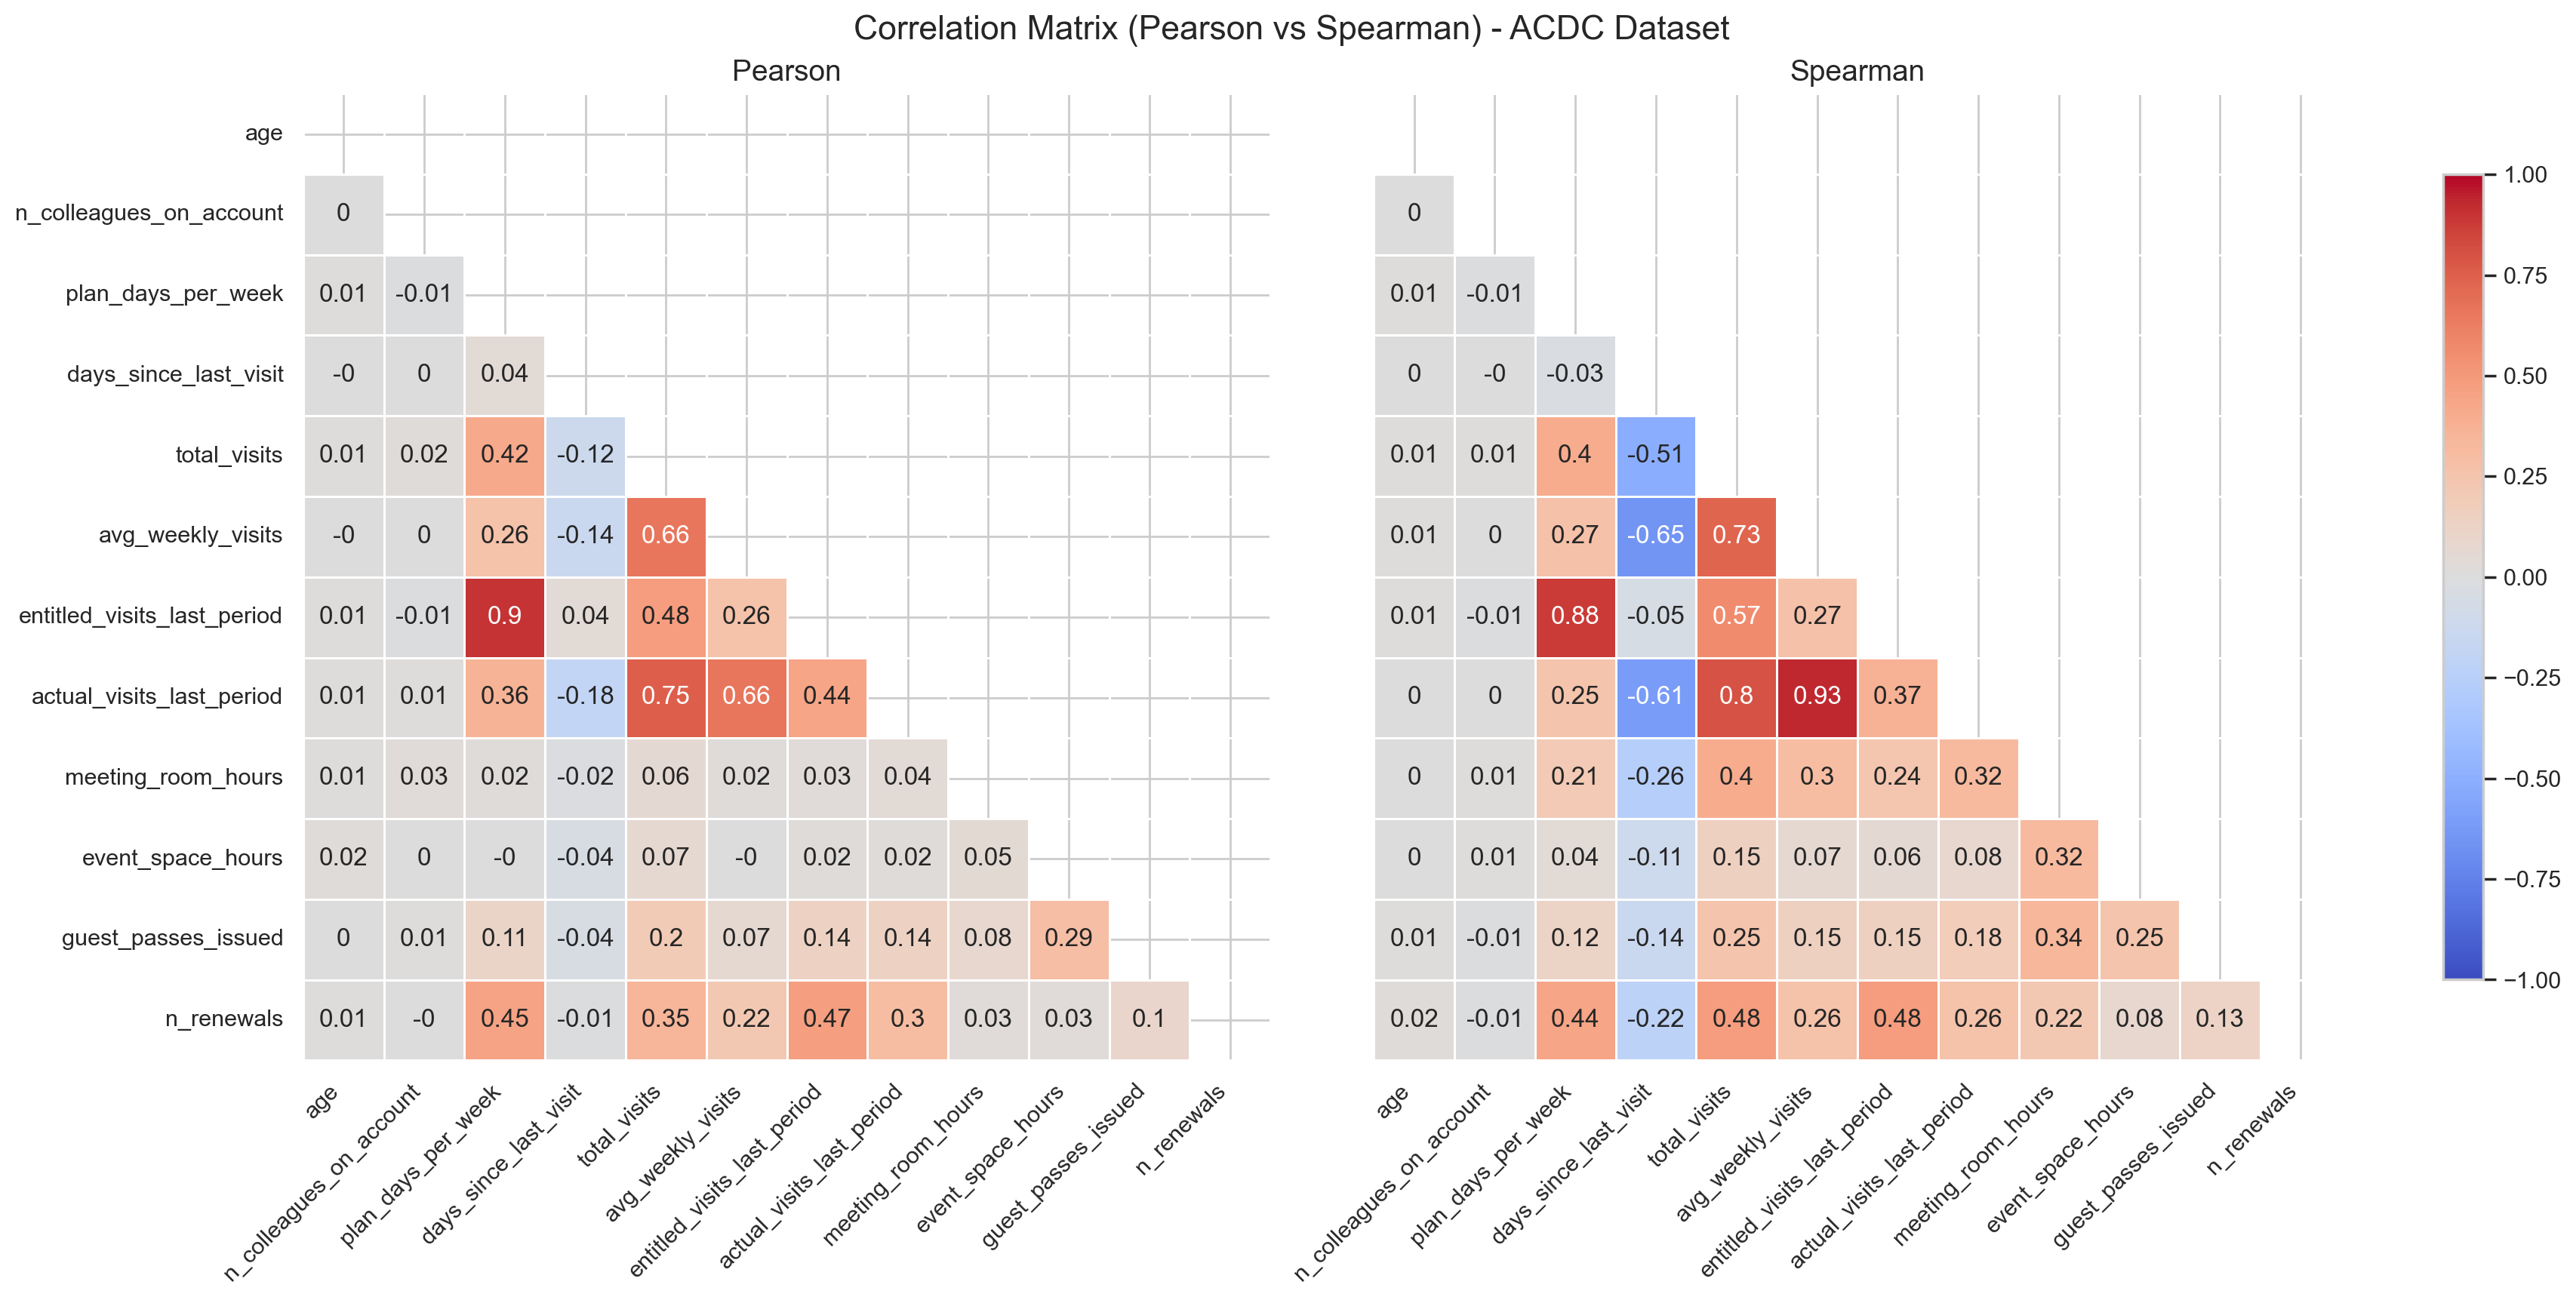

In [60]:
# Pearson (left) and Spearman (right) side by side, on the same colour scale
fig, axes = plt.subplots(1, 2, figsize=(17, 8.5), layout="constrained")

for ax, corr, method in zip(axes, [corr_pearson, corr_spearman], ["Pearson", "Spearman"]):
    sns.heatmap(
        corr.round(2),
        mask=mask,                # hide the upper triangle and the diagonal
        annot=True,               # show the coefficient in each cell
        cmap="coolwarm",          # diverging palette: blue = negative, red = positive
        center=0,                 # centre the colour scale on 0
        linewidths=0.5,           # lines between cells
        vmin=-1, vmax=1,          # same fixed scale for both plots
        square=True,              # square cells
        cbar=False,               # a single shared colour bar is added below
        ax=ax
    )
    ax.set_title(method, fontsize=14)
    ax.tick_params(axis="x", labelrotation=45)
    plt.setp(ax.get_xticklabels(), ha="right")

# The rows are the same in both plots, so the variable names are only shown on the left
axes[1].set_yticks([])

# One colour bar shared by both heatmaps
fig.colorbar(axes[1].collections[0], ax=axes, shrink=0.8)

fig.suptitle("Correlation Matrix (Pearson vs Spearman) - ACDC Dataset", fontsize=16)
plt.show()

In [61]:
# Strongest relationships first, sorted by absolute value (positive or negative)
top_pairs = corr_spearman.where(~mask).stack().sort_values(key=abs, ascending=False)

top_pairs.head(10).round(2).to_frame("Spearman")

Spearman
actual_visits_last_period   avg_weekly_visits                0.93
entitled_visits_last_period plan_days_per_week               0.88
actual_visits_last_period   total_visits                     0.80
avg_weekly_visits           total_visits                     0.73
                            days_since_last_visit           -0.65
actual_visits_last_period   days_since_last_visit           -0.61
entitled_visits_last_period total_visits                     0.57
total_visits                days_since_last_visit           -0.51
n_renewals                  entitled_visits_last_period      0.48
                            total_visits                     0.48

**Conclusions from the correlation analysis:**

- Three pairs have a correlation of 0.8 or higher, meaning they carry almost the same information: `actual_visits_last_period` and `avg_weekly_visits` (0.93), `entitled_visits_last_period` and `plan_days_per_week` (0.88), and `actual_visits_last_period` and `total_visits` (0.80). Keeping both variables of a pair would give that behaviour double weight in the clustering, so one variable of each pair is a candidate to be dropped.
- The strong link between `entitled_visits_last_period` and `plan_days_per_week` supports our earlier hypothesis that the entitled visits are calculated from the plan rather than counted.
- Visit frequency is negatively related to `days_since_last_visit` (between -0.51 and -0.65): members who visit more often have fewer days since their last visit.
- `age` and `n_colleagues_on_account` are practically uncorrelated with all the other variables (|ρ| ≤ 0.02), so they bring independent information about the member's profile rather than their behaviour.